# 02. Unpaid Overtime Analysis (1999–2024)

This notebook extracts and harmonizes data related to unpaid overtime and work boundaries outside regular hours. 
Due to questionnaire changes over the years, the analysis combines:
1. **Binary measure (`K15_3`)** for years up to 2015 (% of respondents who did unpaid overtime).
2. **Frequency measure (`K43G`)** for years from 2016 onwards (% of respondents actively experiencing work-related contacts or overtime outside hours).

In [1]:
# ==========================================
# 1. IMPORTS & CONFIGURATION
# ==========================================

import glob
import os
import pandas as pd

# 1. Dictionary of survey years
fsd_year_mapping = {
    '3049': 2014,
    '3131': 2015,
    '3220': 2016,
    '3481': 2017,
    '3482': 2018,
    '3493': 2019,
    '3645': 2020,
    '3727': 2021,
    '3784': 2022,
    '3914': 2023,
    '4011': 2024,
}


# 2. Function to find year from filename
def get_year(filename):
  for code, year in fsd_year_mapping.items():
    if code in filename:
      return year
  return None


# 3. Function to safely load CSV files
def load_file_safe(file_path):
  for sep in [';', ',']:
    try:
      df = pd.read_csv(
          file_path, sep=sep, low_memory=False, encoding='utf-8-sig'
      )
      if df.shape[1] > 1:
        return df
    except:
      continue
  return None

In [3]:
# ==========================================
# 2. DATA EXTRACTION
# ==========================================

results_unpaid = []

# Find all CSV files starting with daF inside the 'data' subfolder
all_csvs = glob.glob(os.path.join('data', 'daF*.csv'))

for file_path in all_csvs:
  filename = os.path.basename(file_path)
  year = get_year(filename)

  # Skip if year is not recognized
  if year is None:
    continue

  # Load CSV safely using our function
  df = load_file_safe(file_path)
  if df is None:
    continue

  # Create lowercase column lookup dictionary
  cols = {c.lower(): c for c in df.columns}

  # Select column based on survey period (K15_3 for older, K43G for recent years)
  if year <= 2015:
    col_name = cols.get('k15_3')
    measure_type = 'Binary (K15_3: % Yes)'
  else:
    col_name = cols.get('k43g')
    measure_type = 'Frequency (K43G: % Active)'

  # Check if column exists in the dataset
  if col_name and col_name in df.columns:
    s = pd.to_numeric(df[col_name], errors='coerce')

    # Calculate percentage based on scale type
    if year <= 2015:
      valid = s[(s >= 1) & (s <= 2)]
      share = (valid == 1).mean() * 100
    else:
      valid = s[(s >= 1) & (s <= 5)]
      share = (valid <= 4).mean() * 100

    # Save complete detailed results to list
    results_unpaid.append({
        'Year': year,
        'File': filename,
        'Column': col_name.upper(),
        'Measure': measure_type,
        'N': len(valid),
        'Value': round(share, 2),
    })

print(f'Successfully processed {len(results_unpaid)} files for unpaid overtime!')

Successfully processed 9 files for unpaid overtime!


In [4]:
# ==========================================
# 3. DISPLAY & EXPORT RESULTS
# ==========================================

# Check if we have any results
if len(results_unpaid) > 0:

  # Convert list to DataFrame
  df_unpaid_harm = pd.DataFrame(results_unpaid)

  # Sort by year
  df_unpaid_harm = df_unpaid_harm.sort_values('Year')

  # Print table without index numbers
  print(df_unpaid_harm.to_string(index=False))

  # Save table to CSV file
  df_unpaid_harm.to_csv('unpaid_overtime_2014_2024.csv', index=False)
  print('Done! File saved successfully.')

else:
  print('Error: No data found.')

 Year            File Column                    Measure    N  Value
 2016 daF3220_eng.csv   K43G Frequency (K43G: % Active) 1627  38.29
 2017 daF3481_eng.csv   K43G Frequency (K43G: % Active) 1686  37.66
 2018 daF3482_eng.csv   K43G Frequency (K43G: % Active) 1639  35.02
 2019 daF3493_eng.csv   K43G Frequency (K43G: % Active) 1547  38.72
 2020 daF3645_eng.csv   K43G Frequency (K43G: % Active) 1640  35.73
 2021 daF3727_fin.csv   K43G Frequency (K43G: % Active) 1893  42.31
 2022 daF3784_fin.csv   K43G Frequency (K43G: % Active) 1853  39.34
 2023 daF3914_fin.csv   K43G Frequency (K43G: % Active) 1997  37.76
 2024 daF4011_fin.csv   K43G Frequency (K43G: % Active) 2067  35.51
Done! File saved successfully.


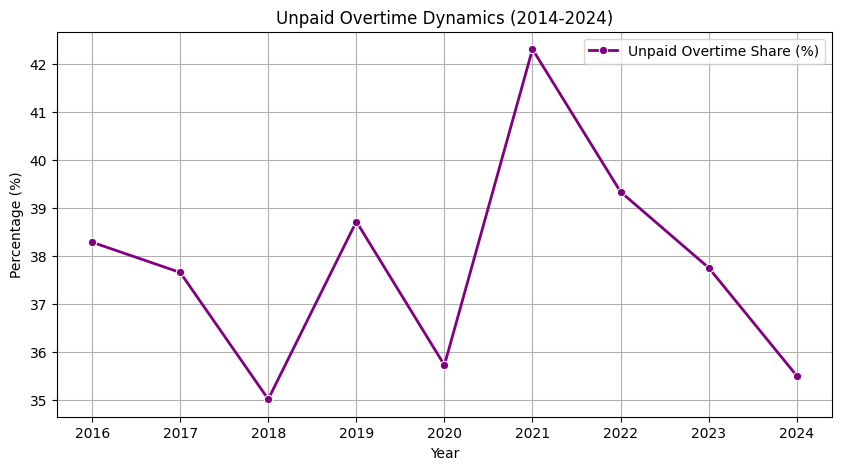

In [5]:
# ==========================================
# 4. PLOT: Unpaid Overtime
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Load data from CSV file
df_plot = pd.read_csv('unpaid_overtime_2014_2024.csv')

# Set figure size
plt.figure(figsize=(10, 5))

# Plot line with purple color and markers
sns.lineplot(
    data=df_plot,
    x='Year',
    y='Value',
    marker='o',
    linewidth=2,
    color='purple',
    label='Unpaid Overtime Share (%)',
)

# Add titles and labels
plt.title('Unpaid Overtime Dynamics (2014-2024)')
plt.xlabel('Year')
plt.ylabel('Percentage (%)')

# Show all years on X-axis
plt.xticks(df_plot['Year'])

# Show grid and legend
plt.grid(True)
plt.legend()

# Save image and display
plt.savefig('unpaid_overtime_trend_2014_2024.png', dpi=300)
plt.show()